# Gate assignment for a connection bank

At a hub airport, flights arrive and leave in waves, so that passengers can change from one flight to another. One such wave is called a *connection bank*: a group of flights that are on the ground at the same time. Each of them stands at a gate, and a connecting passenger walks from the gate of the arriving flight to the gate of the departing one. You decide which flight stands at which gate, and with that, how far your passengers walk.

![A terminal with two piers that branch off a spine. Each pier has 12 pairs of gates that face each other. The gates are numbered 0 to 47, pier by pier, from the spine outwards. Two walks are drawn. The first stays within a pier, from gate 14 to gate 21, and is 240 m long. The second leads to the other pier by way of the spine, from gate 5 to gate 30, and is 720 m long.](figures/gate-assignment.svg)

This decision cannot be taken one flight at a time. The total walking is a sum over pairs of flights: the passengers who change from one flight to the other, times the distance between the two gates. The best gate for a flight therefore depends on where its partner flights stand. Operations research knows this as the quadratic assignment problem.

In this notebook, a bank of 48 flights shares a terminal of 48 gates. If the flights take the gates in timetable order, a connecting passenger walks 700 m on average. Quicopt returns a plan with 305 m in about a second. For comparison, we write the same decision as a mixed-integer linear program (MILP) and give it to HiGHS, an open-source solver, for 30 seconds. After those 30 seconds, HiGHS holds a plan with 643 m, and the most it can prove is that the walking is not negative.

The number of flights and the number of departures that each arrival connects to are set in one cell, so you can run every step on a bank of your own size.

In [1]:
%pip install "quicopt[pyomo]" highspy matplotlib

## Parameters

Three numbers describe the experiment. Every cell below reads them, so you can change them in this one cell and run the notebook again.

In [2]:
flights = 48               # flights in the bank; the terminal has one gate for each
partner_departures = 4     # departures that the passengers of one arrival connect to
time_limit = 30            # seconds that each solver may take

## The terminal

The terminal has one gate for every flight of the bank. Its piers branch off a straight spine, 150 m apart. Each pier has 24 gates in 12 pairs that face each other. The first pair lies 60 m from the spine, and each further pair lies 70 m further out. The gates are numbered pier by pier, from the spine outwards, as in the picture above.

A walk within one pier is the distance along the pier plus 30 m. A walk to another pier leads in to the spine, along the spine and out again, and changing piers adds 100 m.

In [3]:
import numpy as np

GATES_PER_PIER = 24


def gate_positions(gates):
    """The pier of every gate, and how far out along its pier the gate lies.

    Args:
        gates: Number of gates. They fill one pier after the other.

    Returns:
        Two arrays with one entry per gate: the number of its pier, and the
        metres from the spine along the pier to the gate.
    """
    gate = np.arange(gates)
    pier = gate // GATES_PER_PIER
    along_pier = 60.0 + 70.0 * ((gate % GATES_PER_PIER) // 2)
    return pier, along_pier


def walking_distances(gates):
    """Metres that a passenger walks between every two gates.

    Args:
        gates: Number of gates.

    Returns:
        Square array: entry [g, h] is the walk from gate g to gate h.
    """
    pier, along_pier = gate_positions(gates)
    same_pier = pier[:, None] == pier[None, :]                   # [g, h]: are gates g and h on one pier?
    within_pier = np.abs(along_pier[:, None] - along_pier[None, :]) + 30.0
    along_spine = 150.0 * np.abs(pier[:, None] - pier[None, :])
    to_other_pier = along_pier[:, None] + along_spine + along_pier[None, :] + 100.0
    distance = np.where(same_pier, within_pier, to_other_pier)
    np.fill_diagonal(distance, 0.0)
    return distance


distance = walking_distances(flights)
pier, along_pier = gate_positions(flights)

print(f"gates: {flights}, piers: {pier.max() + 1}")
for g, h in [(0, 1), (14, 21), (5, 30)]:
    if h < flights:
        print(f"from gate {g:2} to gate {h:2}: {distance[g, h]:5.0f} m")
print(f"longest walk between two gates: {distance.max():,.0f} m")

gates: 48, piers: 2
from gate  0 to gate  1:    30 m
from gate 14 to gate 21:   240 m
from gate  5 to gate 30:   720 m
longest walk between two gates: 1,910 m


Gates 0 and 1 face each other. Gates 14 and 21 lie on the same pier, and gates 5 and 30 on different piers. The picture above shows these two walks.

## The connecting passengers

Every flight of the bank lands, stands at its gate and takes off again. Some of its arriving passengers leave on another flight of the bank. The array entry `transfers[i, j]` counts the passengers who arrive on flight `i` and leave on flight `j`. A pair of flights with at least one such passenger is a *connection*.

We draw the passengers at random from a fixed seed, so you can reproduce every number on this page. The first third of the flights are long-haul flights, which bring 150 to 250 connecting passengers each. The others are short-haul flights and bring 30 to 80. The passengers of one arrival spread unevenly over `partner_departures` other flights.

In [4]:
def transfer_passengers(flights, partner_departures, seed=0):
    """Connecting passengers between the flights of a bank, drawn at random.

    Args:
        flights: Number of flights in the bank.
        partner_departures: Number of other flights over which the passengers
            of one arrival spread.
        seed: Seed of the random numbers. The same seed gives the same bank.

    Returns:
        Square array: entry [i, j] is the number of passengers who arrive on
        flight i and leave on flight j.
    """
    rng = np.random.default_rng(seed)
    long_haul = np.arange(flights) < flights // 3
    transfers = np.zeros((flights, flights))
    for arrival in range(flights):
        connecting = rng.uniform(150, 250) if long_haul[arrival] else rng.uniform(30, 80)
        other_flights = [flight for flight in range(flights) if flight != arrival]
        partners = rng.choice(other_flights, partner_departures, replace=False)
        share = rng.lognormal(0, 1, partner_departures)          # uneven shares of the passengers
        transfers[arrival, partners] = np.round(connecting * share / share.sum())
    return transfers


transfers = transfer_passengers(flights, partner_departures)
passengers = transfers.sum()                       # all connecting passengers of the bank
arrival, departure = np.nonzero(transfers)         # connection k leads from flight arrival[k] to flight departure[k]
largest_first = np.argsort(-transfers[arrival, departure], kind="stable")     # the connections, largest first

print(f"{passengers:,.0f} connecting passengers on {len(arrival)} connections")
print("the five largest connections:")
for k in largest_first[:5]:
    print(f"  from flight {arrival[k]:2} to flight {departure[k]:2}: {transfers[arrival[k], departure[k]]:3.0f} passengers")

4,976 connecting passengers on 191 connections
the five largest connections:
  from flight 10 to flight  5: 175 passengers
  from flight  8 to flight 29: 154 passengers
  from flight  3 to flight 46: 114 passengers
  from flight  0 to flight 15:  96 passengers
  from flight  2 to flight  4:  92 passengers


With 48 arrivals and 4 partner departures each, 192 pairs of flights are drawn. One of them receives a share that rounds to no passenger, so the bank has 191 connections.

## The walking of a gate plan

A gate plan gives every flight its gate. We write it as an array `plan`, in which `plan[i]` is the gate of flight `i`. Its total walking is the sum over all connections of the passengers times the metres between the two gates.

Two kinds of plan need no optimization. In timetable order, flight 0 stands at gate 0, flight 1 at gate 1, and so on. A random plan shuffles the flights over the gates. We draw 1,000 random plans.

In [5]:
def walking(plan, transfers, distance):
    """Total metres that the connecting passengers walk under a gate plan.

    Args:
        plan: Array with the gate of every flight: plan[i] is the gate of flight i.
        transfers: Passengers between the flights, as transfer_passengers returns them.
        distance: Metres between the gates, as walking_distances returns them.

    Returns:
        The sum over all connections of passengers times metres.
    """
    between_flights = distance[plan][:, plan]      # [i, j]: metres between the gates of flights i and j
    return float((transfers * between_flights).sum())


def show(label, metres):
    """Print the total walking of a plan and the average walk of a connecting passenger.

    Args:
        label: Name of the plan.
        metres: Its total walking in metres.
    """
    print(f"{label:30} {metres:12,.0f} m in total  {metres / passengers:6.0f} m per passenger")


timetable_order = np.arange(flights)               # flight i stands at gate i
rng = np.random.default_rng(1)                     # the seed of the random plans
walking_of_random_plans = [walking(rng.permutation(flights), transfers, distance) for _ in range(1000)]

show("timetable order", walking(timetable_order, transfers, distance))
show("1,000 random plans, average", np.mean(walking_of_random_plans))
show("1,000 random plans, best", np.min(walking_of_random_plans))

timetable order                   3,481,450 m in total     700 m per passenger
1,000 random plans, average       3,678,339 m in total     739 m per passenger
1,000 random plans, best          2,721,810 m in total     547 m per passenger


In timetable order, a connecting passenger walks 700 m on average. Random plans need 739 m on average, and the best of the 1,000 needs 547 m.

## The gate plan as a permutation

A gate plan places 48 flights at 48 gates, one flight per gate. Such a placement is a permutation, and `quicopt.structured.permutation` declares one as the decision of a Pyomo model. A permutation in Quicopt places *items* in *slots*. In this model the flights are the items and the gates are the slots, so `gate.slot_of(i)` is the gate of flight `i`. Quicopt chooses these values, like decision variables.

The walk between two flights depends on gates that are not chosen yet, and a NumPy array cannot be indexed by a decision. A `lookup_table` can: `walk[gate.slot_of(i), gate.slot_of(j)]` is the distance between the gates of flights `i` and `j`.

The objective is then the sum from the previous section: for every connection, the passengers times the metres between the two gates. The model needs no constraints, because a permutation already gives every flight one gate and every gate one flight.

`client.solve` sends the model to the Quicopt service and returns its result. The service may take at most `time_limit` seconds.

In [6]:
import pyomo.environ as pyo
from quicopt import Client
from quicopt.structured import permutation, lookup_table

client = Client()                                      # the connection to the Quicopt service


def plan_with_quicopt(transfers, distance, time_limit):
    """Ask Quicopt for the gate plan with the least total walking.

    Args:
        transfers: Passengers between the flights.
        distance: Metres between the gates.
        time_limit: Seconds that the service may take.

    Returns:
        The service's result. Its structures["gate"].slot_of lists the gate
        of every flight.
    """
    flights = len(transfers)
    model = pyo.ConcreteModel()
    walk = lookup_table(model, "walk", distance)       # walk[g, h]: metres between gates g and h
    gate = permutation(model, "gate", flights)         # gate.slot_of(i): the gate of flight i
    model.walking = pyo.Objective(sense=pyo.minimize, expr=sum(
        float(transfers[i, j]) * walk[gate.slot_of(i), gate.slot_of(j)]
        for i in range(flights) for j in range(flights) if transfers[i, j]))
    return client.solve(model, time_limit=time_limit)


result = plan_with_quicopt(transfers, distance, time_limit)
print(result.display)

▄▀▀▀▄        ▄                     █
█   █ █   █ ▄▄  ▄▀▀▀▄ ▄▀▀▀▄ █▀▀▀▄ ▀█▀▀
█ ▀▄▀ █   █  █  █   ▄ █   █ █▄▄▄▀  █  ▄
 ▀▀ ▀  ▀▀▀▀ ▀▀▀  ▀▀▀   ▀▀▀  █       ▀▀

├── shots
│   └── 1 · primal   1518140   0.61s  ◀ best
├── status:     heuristic
├── feasible:   true
├── objective:  1.51814e6
├── x:          —  (0 variables)
├── structures: gate: item_at=[20, 43, 11, 6, 36, 7, 21, 10, …]
├── time_limit: 30 s
└── solve_time: 0.6223 s

    Intel Xeon Gold 6338N @ 2.20GHz · 16 cores, 1 core per shot


The service was allowed 30 seconds and reports a solve time of less than one. The line `status: heuristic` says that Quicopt found the plan by a search and does not prove that no plan is better. The plan itself is listed under `structures`. The line `x` is empty, because the model has no variables besides the permutation. The last lines name the hardware of the service, which used one core.

We check the returned plan against the data. It must use every gate exactly once, and its walking, recomputed with `walking`, must equal the objective that Quicopt reports.

In [7]:
quicopt_plan = np.array(result.structures["gate"].slot_of)       # quicopt_plan[i]: the gate of flight i
assert sorted(quicopt_plan) == list(range(flights))              # every gate holds exactly one flight
quicopt_walking = walking(quicopt_plan, transfers, distance)

print(f"walking that Quicopt reports      {result.objective:12,.0f} m")
print(f"walking recomputed from the data  {quicopt_walking:12,.0f} m\n")
show("Quicopt's plan", quicopt_walking)
print(f"less than timetable order:               {1 - quicopt_walking / walking(timetable_order, transfers, distance):.0%}")
print(f"less than the best of the random plans:  {1 - quicopt_walking / np.min(walking_of_random_plans):.0%}")

walking that Quicopt reports         1,518,140 m
walking recomputed from the data     1,518,140 m

Quicopt's plan                    1,518,140 m in total     305 m per passenger
less than timetable order:               56%
less than the best of the random plans:  44%


The recomputed walking equals the reported objective. In Quicopt's plan, a connecting passenger walks 305 m on average. The plan needs 56% less walking than timetable order and 44% less than the best of the 1,000 random plans.

## The plan in the terminal

The next cell draws the terminal twice, in timetable order and with Quicopt's plan. Each square is a gate. A darker square holds a flight with more connecting passengers. An orange line joins the two gates of a connection, and a wider line stands for more passengers. Only the largest eighth of the connections are drawn.

the 23 connections drawn carry 40% of the connecting passengers


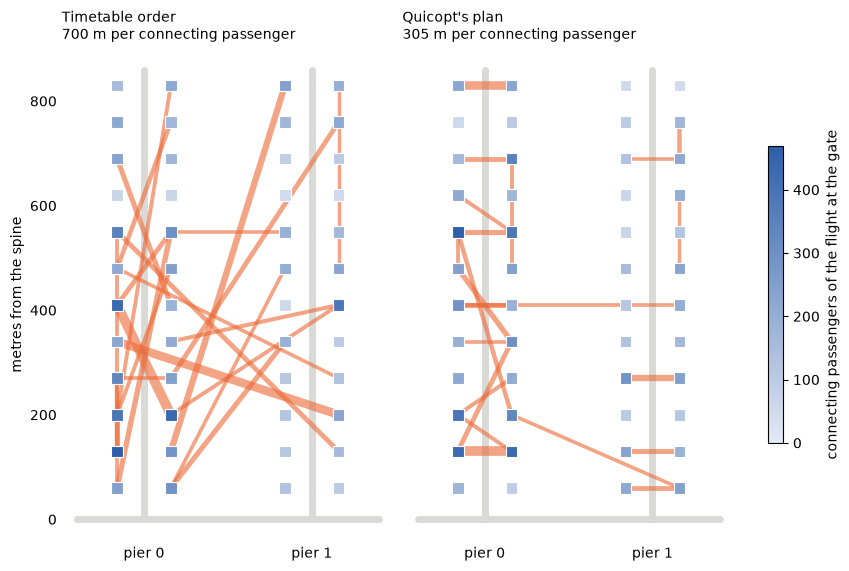

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

BLUE, ORANGE, GREY = "#2d5faa", "#eb6834", "#d9d9d6"
shades = LinearSegmentedColormap.from_list("shades", ["#e3e9f4", BLUE])

piers = pier.max() + 1
gate_x = 150.0 * pier + np.where(np.arange(flights) % 2 == 0, -24.0, 24.0)     # the two gates of a pair, left and right of their pier
flight_passengers = transfers.sum(axis=0) + transfers.sum(axis=1)              # passengers who arrive or leave on each flight
drawn = largest_first[:len(largest_first) // 8]                                # the largest eighth of the connections
print(f"the {len(drawn)} connections drawn carry {transfers[arrival[drawn], departure[drawn]].sum() / passengers:.0%} of the connecting passengers")

figure, panels = plt.subplots(1, 2, figsize=(min(13.0, 4.0 + 2.2 * piers), 5.6), sharey=True, constrained_layout=True)
for panel, plan, title in [(panels[0], timetable_order, "Timetable order"), (panels[1], quicopt_plan, "Quicopt's plan")]:
    panel.plot([-60, 150 * (piers - 1) + 60], [0, 0], color=GREY, lw=5, solid_capstyle="round")              # the spine
    for p in range(piers):
        panel.plot([150 * p, 150 * p], [0, along_pier.max() + 30], color=GREY, lw=5, solid_capstyle="round")        # a pier
    for k in drawn:
        g, h = plan[arrival[k]], plan[departure[k]]              # the gates of the two flights of connection k
        panel.plot([gate_x[g], gate_x[h]], [along_pier[g], along_pier[h]], color=ORANGE, alpha=0.6,
                   lw=transfers[arrival[k], departure[k]] / 25, solid_capstyle="round")       # 1 point of width per 25 passengers
    passengers_at_gate = np.empty(flights)
    passengers_at_gate[plan] = flight_passengers                 # gate plan[i] holds flight i
    squares = panel.scatter(gate_x, along_pier, c=passengers_at_gate, cmap=shades, vmin=0, vmax=flight_passengers.max(),
                            marker="s", s=70, edgecolor="white", linewidth=0.8, zorder=3)
    panel.set_title(f"{title}\n{walking(plan, transfers, distance) / passengers:.0f} m per connecting passenger",
                    loc="left", fontsize=10)
    panel.set_xticks(150 * np.arange(piers), [f"pier {p}" for p in range(piers)])
    panel.tick_params(length=0)
    panel.set_frame_on(False)
panels[0].set_ylabel("metres from the spine")
figure.colorbar(squares, ax=panels, shrink=0.6, label="connecting passengers of the flight at the gate")
plt.show()

Two numbers summarize the picture: the share of the connecting passengers who change piers, and the share who walk at most 100 m, which is the walk to the next pair of gates on the same pier.

In [9]:
connection_passengers = transfers[arrival, departure]             # the passengers of every connection
for label, plan in [("timetable order", timetable_order), ("Quicopt's plan", quicopt_plan)]:
    metres = distance[plan[arrival], plan[departure]]             # the walk of every connection under this plan
    changes_pier = pier[plan[arrival]] != pier[plan[departure]]
    print(f"{label:16} {connection_passengers[changes_pier].sum() / passengers:4.0%} of the passengers change piers, "
          f"{connection_passengers[metres <= 100].sum() / passengers:4.0%} walk at most 100 m")

timetable order   48% of the passengers change piers,   7% walk at most 100 m
Quicopt's plan    20% of the passengers change piers,  51% walk at most 100 m


In timetable order, 48% of the connecting passengers change piers, and the large connections cross the terminal. In Quicopt's plan, 20% change piers, and 51% walk at most 100 m. Most of the connections drawn there join gates that face each other or lie a few pairs apart.

## The same decision as a mixed-integer program

Solvers such as HiGHS, Gurobi and CPLEX expect this decision as a mixed-integer program. The program has a 0/1 variable $x_{ig}$ for every flight $i$ and every gate $g$. The variable is 1 if flight $i$ stands at gate $g$. One row per flight and one row per gate make the plan one-to-one:

$$\sum_{g} x_{ig} = 1 \quad\text{for every flight } i, \qquad\qquad \sum_{i} x_{ig} = 1 \quad\text{for every gate } g.$$

Let $T_{ij}$ be the passengers from flight $i$ to flight $j$ (`transfers`) and $D_{gh}$ the metres between gates $g$ and $h$ (`distance`). The total walking is

$$\sum_{i,j} T_{ij} \sum_{g,h} D_{gh}\, x_{ig}\, x_{jh}.$$

Every term is a product of two 0/1 variables, so the objective is quadratic. HiGHS solves linear programs with integer variables, so the products have to be rewritten with linear rows. The linearization of Kaufman and Broeckx is a standard and compact way to do that. It adds one continuous variable $w_{ig} \ge 0$ and one row for every flight $i$ and gate $g$:

$$w_{ig} \;\ge\; \sum_{j}\sum_{h} E_{ij}\, D_{gh}\, x_{jh} \;-\; M_{ig}\,(1 - x_{ig}).$$

In this row, $E_{ij} = T_{ij} + T_{ji}$ counts the passengers between flights $i$ and $j$ in both directions. Passengers walk the same distance in both directions. If flight $i$ stands at gate $g$, the row makes $w_{ig}$ at least the metres that the passengers of flight $i$ walk, on arrival and on departure. If flight $i$ stands elsewhere, the constant $M_{ig}$ switches the row off. $M_{ig}$ is the walk of these passengers if all of them had to reach the gate furthest from $g$. No plan asks for more. Such a row is known as a big-M row. Every passenger is counted at two flights, on arrival and on departure, so the program minimizes $\tfrac{1}{2} \sum_{i,g} w_{ig}$.

The size of this program can be counted without building it:

In [10]:
def linearized_size(transfers):
    """Size of the linearized program for a bank, counted without building it.

    Args:
        transfers: Passengers between the flights.

    Returns:
        The numbers of columns, rows and nonzero coefficients.
    """
    flights = len(transfers)
    exchange = transfers + transfers.T                  # E[i, j]: passengers between flights i and j, both directions
    partner_pairs = np.count_nonzero(exchange)          # pairs (i, j) with E[i, j] > 0
    columns = 2 * flights**2                            # x[i, g] and w[i, g]
    rows = 2 * flights + flights**2                     # one per flight, one per gate, one per w[i, g]
    one_to_one = 2 * flights**2                         # nonzeros of the rows per flight and per gate
    # the row of w[i, g] holds w[i, g], x[i, g], and x[j, h] for every partner j of i and every other gate h
    walking_rows = 2 * flights**2 + partner_pairs * flights * (flights - 1)
    return columns, rows, one_to_one + walking_rows


columns, rows, nonzeros = linearized_size(transfers)
print(f"{columns:,} columns, {columns // 2:,} of them 0/1")
print(f"{rows:,} rows")
print(f"{nonzeros:,} nonzeros")

4,608 columns, 2,304 of them 0/1
2,400 rows
821,376 nonzeros


Almost all of the 821,376 nonzero coefficients sit in the rows for $w_{ig}$. Each of these rows holds one coefficient for every partner flight of $i$ at every other gate.

We write the program with `highspy`, the Python interface of HiGHS, and give HiGHS the same 30 seconds. HiGHS runs on one thread, because the service also used one core. Besides a plan, HiGHS returns a lower bound. No plan can walk less than the lower bound, so the gap between the bound and a plan's walking tells how far that plan can be from the best one.

For a bank of more than 60 flights, the cell prints a notice and skips HiGHS, because the program becomes too large to build in a notebook.

In [11]:
import highspy

LARGEST_BANK_FOR_HIGHS = 60        # flights; a larger bank's linearized program is not built here


def plan_with_highs(transfers, distance, time_limit):
    """Build the linearized program and solve it with HiGHS on one thread.

    Args:
        transfers: Passengers between the flights.
        distance: Metres between the gates.
        time_limit: Seconds that HiGHS may take.

    Returns:
        The best plan that HiGHS found in the time (None if it found none),
        and its lower bound on the total walking.
    """
    flights = len(transfers)
    F = G = range(flights)                                   # the flights i, j and the gates g, h
    exchange = transfers + transfers.T                       # E[i, j]
    milp = highspy.Highs()
    milp.setOptionValue("output_flag", False)                # no solver log
    milp.setOptionValue("time_limit", float(time_limit))
    milp.setOptionValue("threads", 1)
    at = milp.addBinaries(F, G)                              # x[i, g] = 1: flight i stands at gate g
    walk = milp.addVariables(F, G)                           # w[i, g] >= 0
    milp.addConstrs(milp.qsum(at[i, g] for g in G) == 1 for i in F)      # every flight stands at one gate
    milp.addConstrs(milp.qsum(at[i, g] for i in F) == 1 for g in G)      # every gate holds one flight
    for i in F:
        partners = np.flatnonzero(exchange[i])               # the flights j with E[i, j] > 0
        for g in G:
            longest = float(exchange[i].sum() * distance[g].max())       # M[i, g]
            walked = milp.qsum(float(exchange[i, j] * distance[g, h]) * at[j, h]
                               for j in partners for h in G if h != g)
            milp.addConstr(walk[i, g] >= walked - longest * (1 - at[i, g]))
    milp.minimize(0.5 * milp.qsum(walk[i, g] for i in F for g in G))
    info = milp.getInfo()
    lower_bound = info.mip_dual_bound
    if info.primal_solution_status != highspy.SolutionStatus.kSolutionStatusFeasible:
        return None, lower_bound
    value = milp.vals(at)                                    # the values of x[i, g] in the best plan
    plan = np.array([max(G, key=lambda g: value[i, g]) for i in F])      # the gate g with x[i, g] = 1
    return plan, lower_bound


if flights <= LARGEST_BANK_FOR_HIGHS:
    highs_plan, lower_bound = plan_with_highs(transfers, distance, time_limit)
    show("timetable order", walking(timetable_order, transfers, distance))
    if highs_plan is None:
        print(f"HiGHS found no plan in {time_limit} s")
    else:
        assert sorted(highs_plan) == list(range(flights))        # every gate holds exactly one flight
        show(f"HiGHS after {time_limit} s", walking(highs_plan, transfers, distance))
    show(f"Quicopt after {result.solve_time_seconds:.1f} s", quicopt_walking)
    print(f"\nHiGHS's lower bound on the total walking: {lower_bound:,.0f} m")
else:
    print(f"{flights} flights are more than {LARGEST_BANK_FOR_HIGHS}: the linearized program is not built")

timetable order                   3,481,450 m in total     700 m per passenger
HiGHS after 30 s                  3,200,870 m in total     643 m per passenger
Quicopt after 0.6 s               1,518,140 m in total     305 m per passenger

HiGHS's lower bound on the total walking: 0 m


After 30 seconds, HiGHS holds a plan with 643 m per passenger, against 700 m in timetable order and 305 m in Quicopt's plan. HiGHS's lower bound is 0, so HiGHS has proven no more than that the walking is not negative. A bound of 0 also leaves open how far Quicopt's plan is from the best one.

This section compares Quicopt with one open-source solver on one linearization. HiGHS stops at the time limit, so its plan depends on the speed of your machine and changes from run to run, while Quicopt ran on the hardware of the service. Other solvers and other formulations may do better, and `plan_with_highs` is the function to change if you want to try one.

## Larger banks

The Quicopt model does not change with the size of the bank. Only its two arrays grow. Below, the same function plans three banks of 48, 96 and 192 flights, whose arrivals connect to 4, 5 and 6 departures. For each bank, the table also states how many nonzero coefficients the linearized program would have.

In [12]:
banks = [(48, 4), (96, 5), (192, 6)]       # the flights and the partner departures of each bank

print("flights  connections   m per passenger in    m per passenger in   Quicopt's    nonzeros of the")
print("                       timetable order       Quicopt's plan       solve time   linearized program")
for bank_flights, bank_partners in banks:
    bank_transfers = transfer_passengers(bank_flights, bank_partners)
    bank_distance = walking_distances(bank_flights)
    bank_result = plan_with_quicopt(bank_transfers, bank_distance, time_limit)
    bank_plan = np.array(bank_result.structures["gate"].slot_of)
    assert sorted(bank_plan) == list(range(bank_flights))        # every gate holds exactly one flight
    in_timetable_order = walking(np.arange(bank_flights), bank_transfers, bank_distance) / bank_transfers.sum()
    in_quicopts_plan = walking(bank_plan, bank_transfers, bank_distance) / bank_transfers.sum()
    print(f"{bank_flights:7}  {np.count_nonzero(bank_transfers):11,}   {in_timetable_order:15,.0f}       {in_quicopts_plan:14,.0f}"
          f"       {bank_result.solve_time_seconds:7.1f} s   {linearized_size(bank_transfers)[2]:18,}")

flights  connections   m per passenger in    m per passenger in   Quicopt's    nonzeros of the
                       timetable order       Quicopt's plan       solve time   linearized program


     48          191               700                  305           0.7 s              821,376


     96          478               980                  464           7.8 s            8,518,464


    192        1,146             1,306                  711           5.1 s           83,099,520


For 96 flights, a connecting passenger walks 464 m in Quicopt's plan, against 980 m in timetable order. For 192 flights, it is 711 m against 1,306 m. Each plan comes back in less than ten seconds. The linearized program for the largest bank would have 83 million nonzero coefficients.

**Reference:** L. Kaufman, F. Broeckx, *An algorithm for the quadratic assignment problem using Benders' decomposition*, European Journal of Operational Research, 1978.